# Лабораторна робота 4

**Виконала:** Проніна Катерина Сергіївна

**Група:** КМ-51

**Датасет:** DS1 

## Мета роботи

Дослідити алгоритми знаходження зв'язаних областей та алгоритми побудови діаграм Вороного. Розділити датасет на зв'язані області, знайти їх центри ваги та побудувати діаграму Вороного за множиною цих центрів.

## Хід роботи

- Дослідити алгоритми знаходження зв'язаних областей та алгоритми побудови діаграм Вороного.
- Використати датасет **DS1** з лабораторної роботи №2.
- Розділити датасет на зв'язані області, знайти центри ваги областей, побудувати діаграму Вороного.
- Відобразити результат на полотні 960×540 пкс та зберегти його у графічний файл.

### Теоретичні відомості

**Зв'язана область (компонента зв'язності).** Усі точки датасету мають один колір (решта полотна — фон), тому зв'язана область — це множина точок, будь-які дві з яких можна з'єднати ланцюжком сусідніх точок цієї ж множини, і між якими немає точок іншого кольору. Сусідство задають двома способами:
- *4-зв'язність* — сусідами є точки, що мають спільну сторону (ліворуч, праворуч, вгору, вниз);
- *8-зв'язність* — додатково враховуються діагональні сусіди (у цій роботі використано саме її).

Алгоритми: **обхід у ширину/глибину (flood fill)** — O(n); **union-find (система неперетинних множин)**; **двопрохідний алгоритм Розенфельда–Пфальца** (маркування компонент у растрі). Застосування: обробка зображень та розпізнавання образів (виділення об'єктів, OCR), аналіз геоданих, медична візуалізація.

**Центр ваги** області — середнє арифметичне координат усіх її точок: $x_c=\frac{1}{k}\sum x_i$, $y_c=\frac{1}{k}\sum y_i$.

**Діаграма Вороного** для множини точок-«сайтів» (тут — центрів ваги) — розбиття площини на комірки, кожна з яких складається з точок, що ближчі до свого сайту, ніж до будь-якого іншого. Комірки — опуклі многокутники, а діаграма є *дуальною* до тріангуляції Делоне. Алгоритми: **Форчуна (заметаюча пряма)** — O(n log n); через тріангуляцію Делоне; «розділяй і володарюй»; інкрементальний. Застосування: найближчі сусіди та геолокаційні задачі (найближча станція/лікарня), аналіз територій, генерація текстур і карт у комп'ютерній графіці, моделювання росту кристалів, планування руху роботів.

## Необхідно написати програму, яка:

1. Зчитує датасет з файлу;
2. Ділить датасет на зв'язані області (множини точок однакового кольору, між якими немає точок іншого кольору);
3. Знаходить центри ваги зв'язаних областей (середнє арифметичне по кожній координаті);
4. Будує діаграму Вороного за множиною центрів ваги;
5. Встановлює розміри вікна (полотна — canvas size) **960×540** пкс;
6. Відображає центри ваги кругами діаметром 5 пкс та побудовану діаграму Вороного;
7. Відображає точки вихідного датасету на побудованому малюнку чорним кольором з насиченістю 10%;
8. Виводить результати у файл графічного формату (PNG).

## Програма

### 1. Імпорт бібліотек

In [4]:
from collections import deque
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.patches import Circle
from scipy.spatial import Voronoi          # побудова діаграми Вороного
from scipy import ndimage                  # лише для перевірки пошуку зв'язаних областей
from PIL import Image

### 2. Зчитування датасету

In [5]:
data_file = Path("DS1.txt")
output_dir = Path(".")

CANVAS_W, CANVAS_H, DPI = 960, 540, 100

points = np.loadtxt(data_file, dtype=int)   # кожен рядок файлу: "x y"
print(f"Зчитано {len(points)} точок з файлу {data_file}.")

Зчитано 45915 точок з файлу DS1.txt.


### 3. Пошук зв'язаних областей

Реалізовано обхід у ширину (BFS): беремо довільну необроблену точку, додаємо її до нової області й по черзі розглядаємо її сусідів; кожен знайдений сусід переходить зі множини «необроблених» до області. Коли черга спорожніє — область завершена. Складність алгоритму O(n), оскільки кожну точку обробляємо один раз, а перевірка належності до множини `set` виконується за O(1).

In [ ]:
NEIGHBORS_8 = [(dx, dy) for dx in (-1, 0, 1) for dy in (-1, 0, 1) if (dx, dy) != (0, 0)]
NEIGHBORS_4 = [(1, 0), (-1, 0), (0, 1), (0, -1)]


def find_regions(pts, neighbors=NEIGHBORS_8):
    """Ділить множину точок на зв'язані області (BFS). Повертає список масивів (k_i × 2)."""
    remaining = set(map(tuple, pts.tolist()))   # ще не віднесені до жодної області
    regions = []
    while remaining:
        seed = remaining.pop()
        region, queue = [seed], deque([seed])
        while queue:
            x, y = queue.popleft()
            for dx, dy in neighbors:
                nb = (x + dx, y + dy)
                if nb in remaining:
                    remaining.remove(nb)
                    region.append(nb)
                    queue.append(nb)
        regions.append(np.array(region))
    # впорядкуємо області зліва направо — для стабільної нумерації
    regions.sort(key=lambda r: (r[:, 0].min(), r[:, 1].min()))
    return regions


regions = find_regions(points)                     # 8-зв'язність
regions_4 = find_regions(points, NEIGHBORS_4)      # для порівняння

# незалежна перевірка за допомогою scipy.ndimage.label
raster = np.zeros((CANVAS_H, CANVAS_W), dtype=bool)
raster[points[:, 1], points[:, 0]] = True
labels, n_scipy = ndimage.label(raster, structure=np.ones((3, 3)))

print(f"Зв'язаних областей (8-зв'язність): {len(regions)}")
print(f"Зв'язаних областей (4-зв'язність): {len(regions_4)}  — діагональні «містки» розбивають деякі області")
print(f"Перевірка scipy.ndimage.label:     {n_scipy}  => збігається: {n_scipy == len(regions)}")
print(f"Сума точок по областях = {sum(len(r) for r in regions)} (усього точок: {len(points)})")

Зв'язаних областей (8-зв'язність): 30
Зв'язаних областей (4-зв'язність): 34  — діагональні «містки» розбивають деякі області
Перевірка scipy.ndimage.label:     30  → збігається: True
Сума точок по областях = 45915 (усього точок: 45915)


Для наочності відобразимо знайдені області різними кольорами (проміжна перевірка, не є вимогою завдання).

In [7]:
fig = plt.figure(figsize=(CANVAS_W / DPI, CANVAS_H / DPI), dpi=DPI)
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xlim(0, CANVAS_W)
ax.set_ylim(0, CANVAS_H)

cmap = plt.get_cmap("tab20")
for i, r in enumerate(regions):
    ax.scatter(r[:, 0], r[:, 1], s=1.5, color=cmap(i % 20), marker="s", linewidths=0)

ax.grid(True, alpha=0.3)
ax.tick_params(direction="in", labelsize=7)
ax.tick_params(axis="x", pad=-14)
ax.tick_params(axis="y", pad=-24)
fig.savefig(output_dir / "regions_DS1.png", dpi=DPI)
plt.show()

MemoryError: bad allocation

<Figure size 960x540 with 1 Axes>

### 4. Центри ваги зв'язаних областей

Центр ваги кожної області — середнє арифметичне її координат по кожній осі (`mean(axis=0)`).

In [8]:
centroids = np.array([r.mean(axis=0) for r in regions])    # (число областей × 2), дійсні числа

print(f"{'№':>3} {'точок':>7} {'x_c':>9} {'y_c':>9}")
for i, (r, c) in enumerate(zip(regions, centroids), start=1):
    print(f"{i:>3} {len(r):>7} {c[0]:>9.2f} {c[1]:>9.2f}")

np.savetxt(output_dir / "centers_DS1.txt", centroids, fmt="%.2f")
print(f"\nЦентри ваги ({len(centroids)}) збережено у centers_DS1.txt.")

  №   точок       x_c       y_c
  1    2544    184.42    343.28
  2     972    185.66    434.39
  3    1235    241.64    299.86
  4     993    235.57    442.40
  5    1381    293.52     61.96
  6    2207    282.76    115.67
  7      28    238.21    195.14
  8    2187    293.91    202.90
  9     610    281.46    417.98
 10    1615    288.67    357.29
 11     256    331.31    304.06
 12     999    341.84    418.92
 13     211    349.31    381.16
 14     437    356.86    294.72
 15     482    373.24    446.40
 16    1427    374.05    118.65
 17    3358    422.10    193.25
 18     235    371.28    375.26
 19    1617    421.31     67.65
 20    2358    404.20    329.86
 21     426    406.28    440.05
 22    1101    464.52    119.84
 23    2530    547.87     68.94
 24    2554    561.17    200.29
 25    1114    565.34    128.58
 26    5607    643.33    335.25
 27    1269    643.06    137.97
 28    2464    687.41     75.35
 29    2003    681.15    205.16
 30    1695    735.04    148.07

Центри 

### 5. Діаграма Вороного

`scipy.spatial.Voronoi` (на основі бібліотеки Qhull) будує діаграму за множиною центрів ваги. Скінченні ребра діаграми з'єднують вершини Вороного; нескінченні ребра (промені) продовжуємо у відповідному напрямку далеко за межі полотна — вони все одно будуть обрізані межами осей 0…960 та 0…540.

In [9]:
vor = Voronoi(centroids)


def voronoi_segments(vor, far=3000):
    """Повертає список відрізків діаграми Вороного (нескінченні ребра подовжуються на far пкс)."""
    center = vor.points.mean(axis=0)
    segments = []
    for (p, q), ridge in zip(vor.ridge_points, vor.ridge_vertices):
        ridge = np.asarray(ridge)
        if np.all(ridge >= 0):                       # скінченне ребро
            segments.append(vor.vertices[ridge])
        else:                                        # нескінченне ребро (промінь)
            i = ridge[ridge >= 0][0]                 # єдина скінченна вершина
            t = vor.points[q] - vor.points[p]        # напрямок між двома сайтами
            t = t / np.linalg.norm(t)
            n = np.array([-t[1], t[0]])              # нормаль до ребра
            mid = vor.points[[p, q]].mean(axis=0)
            direction = np.sign(np.dot(mid - center, n)) * n
            segments.append(np.array([vor.vertices[i], vor.vertices[i] + direction * far]))
    return segments


segments = voronoi_segments(vor)
print(f"Вершин діаграми Вороного: {len(vor.vertices)}")
print(f"Ребер діаграми: {len(segments)} (з них нескінченних: {sum(-1 in r for r in vor.ridge_vertices)})")

Вершин діаграми Вороного: 47
Ребер діаграми: 76 (з них нескінченних: 11)


### 6. Відображення результату

Полотно 960×540 пкс, початок координат — у нижньому лівому куті. На малюнку:
- діаграма Вороного — сині лінії;
- точки вихідного датасету — чорні з насиченістю 10% (`alpha = 0.1`); розмір маркера 1 пкс (`s = (72/DPI)²`, бо 1 пт = DPI/72 пкс);
- центри ваги — червоні кола діаметром 5 пкс (радіус 2.5 пкс; оскільки 1 одиниця координат = 1 пкс, `Circle(radius=2.5)`).

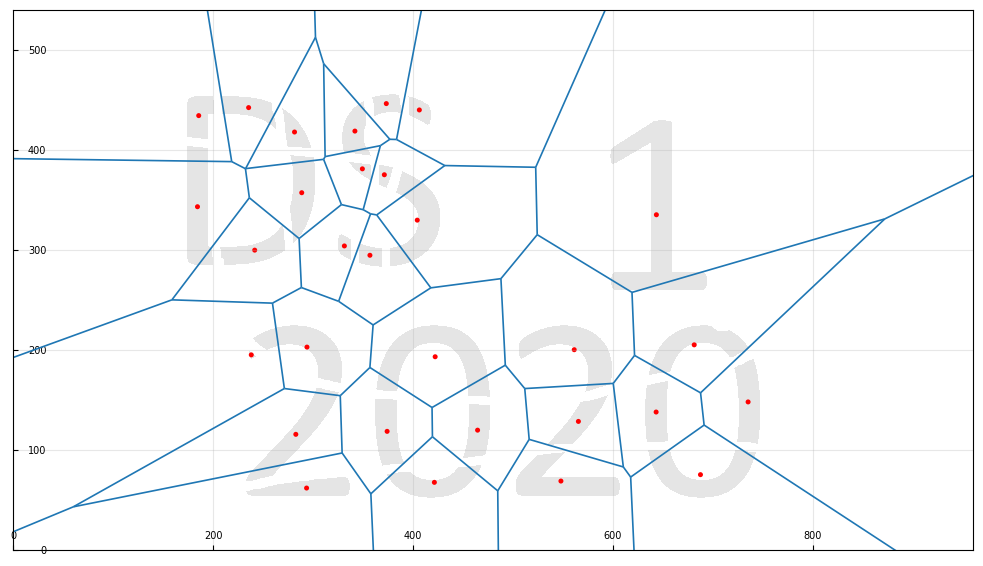

Збережено voronoi_result.png (960 × 540 пкс).


In [10]:
fig = plt.figure(figsize=(CANVAS_W / DPI, CANVAS_H / DPI), dpi=DPI)
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xlim(0, CANVAS_W)
ax.set_ylim(0, CANVAS_H)

# діаграма Вороного
ax.add_collection(LineCollection(segments, colors="tab:blue", linewidths=1.2))

# точки вихідного датасету: чорний колір, насиченість 10%
ax.scatter(points[:, 0], points[:, 1], s=(72 / DPI) ** 2, c="black", alpha=0.1,
           marker="s", linewidths=0)

# центри ваги: кола діаметром 5 пкс
for cx, cy in centroids:
    ax.add_patch(Circle((cx, cy), radius=2.5, facecolor="red", edgecolor="none"))

ax.grid(True, alpha=0.3)
ax.tick_params(direction="in", labelsize=7)
ax.tick_params(axis="x", pad=-14)
ax.tick_params(axis="y", pad=-24)

fig.savefig(output_dir / "voronoi_result.png", dpi=DPI)
plt.show()

with Image.open(output_dir / "voronoi_result.png") as img:
    print(f"Збережено voronoi_result.png ({img.width} × {img.height} пкс).")